# Gosselin 2025 — mouse cochlear nucleus, inferior colliculus and auditory cortex

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/urancon/deepSTRF/blob/develop/examples/inspect_gosselin2025.ipynb)

This notebook is a **visual tour** of the deepSTRF loader for the
**[Gosselin et al. 2025](https://doi.org/10.1371/journal.pbio.3003452)**
(*PLOS Biology*) mouse dataset: the same 307 sounds, 12 repeats each, played to
awake mice while recording the cochlear nucleus (CN) and inferior colliculus
(IC) with Neuropixels and the auditory cortex (AC) with two-photon imaging.

We cover:

- loading an area and the stimulus categories;
- single-neuron responses to a tone and to a natural-like sound;
- the **auditory-nerve model** as an alternative input to the spectrogram;
- the population's best frequencies;
- the leak-aware `group_split`;
- the 2-photon AC data and its calcium lag.

See the [dataset page](../md/README_Gosselin_2025.md) for every metadata key and caveat.

## Setup — Google Colab

The cell below installs deepSTRF from source on Colab. On a local install
(`pip install -e .`) it's a no-op.

**Note on data.** `download=True` fetches only what each call needs from
Zenodo: the sound set (31 MB), then 3.7 GB for IC, 1.5 GB for the
auditory-nerve model and 3.0 GB for AC. If you already have the release
unpacked, point `GOSSELIN2025_DATA` at that folder.

In [1]:
import sys
if 'google.colab' in sys.modules:
    !pip install -q git+https://github.com/urancon/deepSTRF.git
    print("deepSTRF installed from GitHub.")
else:
    print("Local environment — assuming deepSTRF is already importable.")

Local environment — assuming deepSTRF is already importable.


In [2]:
import os
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm in a notebook without ipywidgets
from deepSTRF.datasets.audio import Gosselin2025Dataset
from deepSTRF.utils import plot_stim_with_response

PATH = os.environ.get("GOSSELIN2025_DATA")          # None -> deepSTRF's cache folder
ds = Gosselin2025Dataset(PATH, areas=("IC",), download=PATH is None)

print(f"{ds.N_neurons} IC neurons, {len(ds.stim_meta)} sounds, dt = {ds.dt} ms, "
      f"{ds.stims[0].shape[-1]} bins per trial, {ds.F} spectrogram bands")
print(f"responses[s][n]: {tuple(ds.responses[0][0].shape)} (repeats x time bins)")
for cat, n in sorted(Counter(m["category"] for m in ds.stim_meta).items()):
    print(f"  {cat:18s} {n:3d}")

551 IC neurons, 307 sounds, dt = 5.0 ms, 180 bins per trial, 31 spectrogram bands
responses[s][n]: (12, 180) (repeats x time bins)
  am                  48
  broad_chords        10
  broad_noises        14
  chirps_frequency    10
  chirps_velocity     10
  complex_sounds      60
  decompositions      47
  harmonic_chords      5
  high_chords         11
  low_chords          11
  medium_chords       11
  narrow_noises       10
  pure_tones          28
  ramps               26
  white_noises         6


## A tone and a natural-like sound

Each trial runs from 200 ms before the sound to 700 ms after its onset. We pick
the IC neuron with the strongest response to a 70-dB pure tone at its best
frequency, and show its responses to that tone and to a natural-like clip (a
bird call).

neuron IC_0045: best frequency 20 kHz, spontaneous rate 16.4 spikes/s


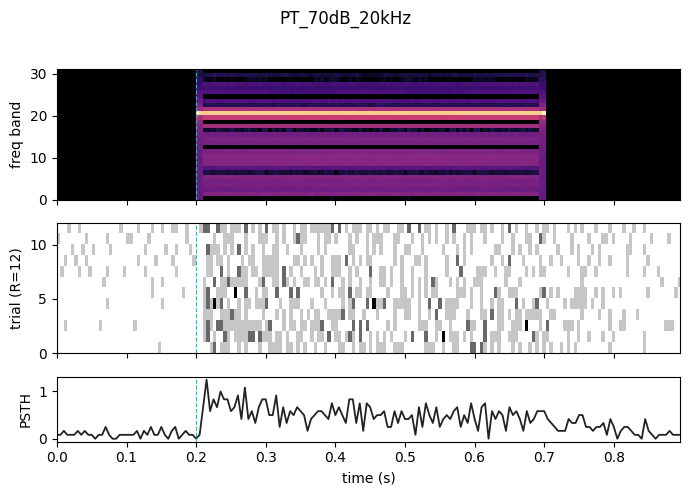

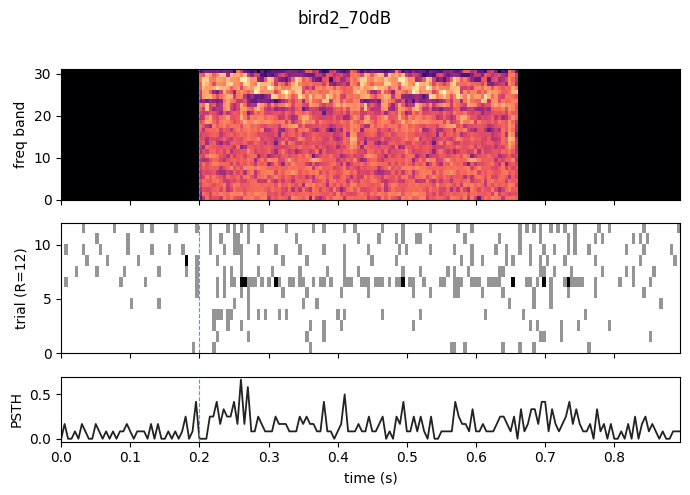

In [3]:
names = [m["name"] for m in ds.stim_meta]
evoked = np.full(ds.N_neurons, -np.inf)
for n, meta in enumerate(ds.nrn_meta):
    if meta["best_freq_khz"] is None:                 # no excitatory response to any tone
        continue
    s = names.index(f"PT_70dB_{meta['best_freq_khz']:g}kHz")
    r = ds.responses[s][n].mean(0).numpy()
    evoked[n] = r[40:140].mean() - r[:40].mean()      # 0-500 ms minus baseline (5 ms bins)
n_best = int(np.argmax(evoked))
bf = ds.nrn_meta[n_best]["best_freq_khz"]
print(f"neuron {ds.nrn_meta[n_best]['cell_id']}: best frequency {bf:g} kHz, "
      f"spontaneous rate {ds.nrn_meta[n_best]['spont_rate']:.1f} spikes/s")

for sound in (f"PT_70dB_{bf:g}kHz", "bird2_70dB"):
    s = names.index(sound)
    fig, axes = plot_stim_with_response(ds.stims[s], ds.responses[s][n_best], dt_ms=ds.dt,
                                        title=sound, figsize=(7, 5))
    for ax in axes:
        ax.axvline(0.2, color="tab:cyan", lw=0.8, ls="--")
    plt.show()

**Reading the figures.** Top: the log spectrogram (31 bands from 2 to 64 kHz,
dB); the sound starts at 0.2 s (dashed line). Middle: spike counts in 5 ms bins
for each of the 12 repeats. Bottom: the PSTH (mean count per bin).

This neuron (best frequency 20 kHz) fires a sharp onset response to its tone
(about 1.2 spikes per 5 ms bin, i.e. ~240 spikes/s) and keeps firing for the
whole 500 ms, then returns to baseline. Its response to the bird call is much
weaker and less regular. Sparse responses to the complex sounds are common in
this IC population, so gate neurons with `compute_neuron_quality()` before
fitting. (The faint horizontal lines in the tone's spectrogram are side-lobes
of the analysis window, not sound.)

## The auditory-nerve model as input

`spec_backend="cochlear_model"` swaps the spectrogram for the release's
biophysical auditory-nerve model, shaped like a spectrogram so any deepSTRF
model can take it. By default it has 51 channels (one per inner hair cell,
ordered by characteristic frequency) in linear spikes/s.

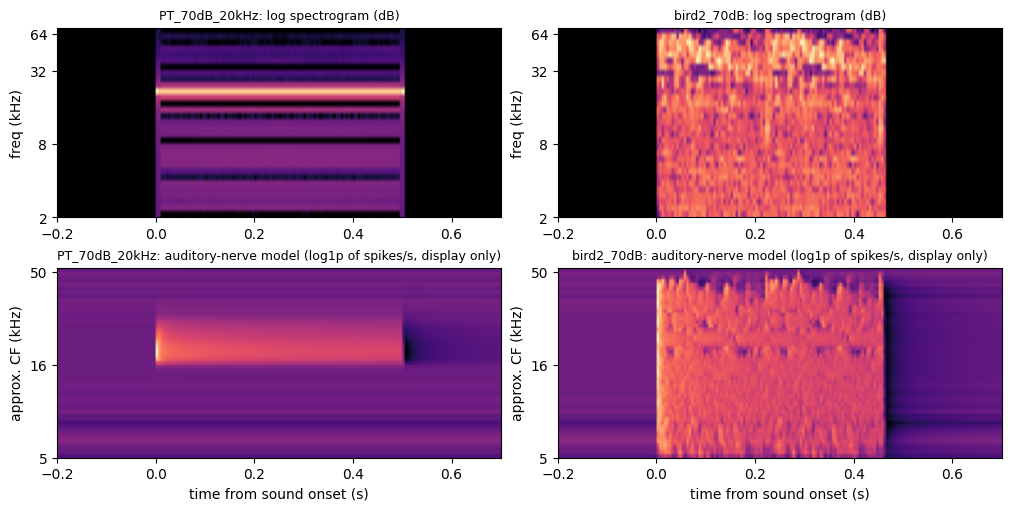

In [4]:
ds_cc = Gosselin2025Dataset(PATH, areas=("IC",), spec_backend="cochlear_model",
                            download=PATH is None)
cf = ds_cc.cochlear_cf_khz
fig, axes = plt.subplots(2, 2, figsize=(10, 5), constrained_layout=True)
t = np.arange(ds.stims[0].shape[-1]) * ds.dt / 1000 - 0.2
for j, sound in enumerate((f"PT_70dB_{bf:g}kHz", "bird2_70dB")):
    s = names.index(sound)
    axes[0, j].imshow(ds.stims[s][0], origin="lower", aspect="auto", cmap="magma",
                      extent=[t[0], t[-1] + ds.dt / 1000, 0, ds.F])
    axes[0, j].set_title(f"{sound}: log spectrogram (dB)", fontsize=9)
    axes[0, j].set_yticks([0, 12, 24, 30], ["2", "8", "32", "64"])
    axes[0, j].set_ylabel("freq (kHz)")
    axes[1, j].imshow(np.log1p(ds_cc.stims[s][0].numpy()), origin="lower", aspect="auto", cmap="magma",
                      extent=[t[0], t[-1] + ds.dt / 1000, 0, len(cf)])
    axes[1, j].set_title(f"{sound}: auditory-nerve model (log1p of spikes/s, display only)", fontsize=9)
    ticks = [0, 25, 50]
    axes[1, j].set_yticks(ticks, [f"{cf[i]:.0f}" for i in ticks])
    axes[1, j].set_ylabel("approx. CF (kHz)")
    axes[1, j].set_xlabel("time from sound onset (s)")
plt.show()

**Spectrogram vs auditory-nerve model.** Top: the log spectrogram. Bottom:
the auditory-nerve model, 51 hair-cell channels ordered by approximate
characteristic frequency (`log1p` applied here for display only; the loader
returns linear rates by default).

The model carries what a spectrogram does not: a strong onset transient,
adaptation during the sound, and a dip below spontaneous firing after the
offset. A 70-dB tone also excites a broad band of fibres, mostly above its own
frequency (through their low-frequency tails), instead of a single line. The
horizontal stripes before the onset are the channels' different spontaneous
rates.

## Best frequencies across the IC population

`nrn_meta['best_freq_khz']` is derived by the loader: the 70-dB pure tone
(14 frequencies, 2–60 kHz) with the largest evoked response.

81 of 551 IC neurons respond to none of the 70-dB tones (best_freq_khz = None)


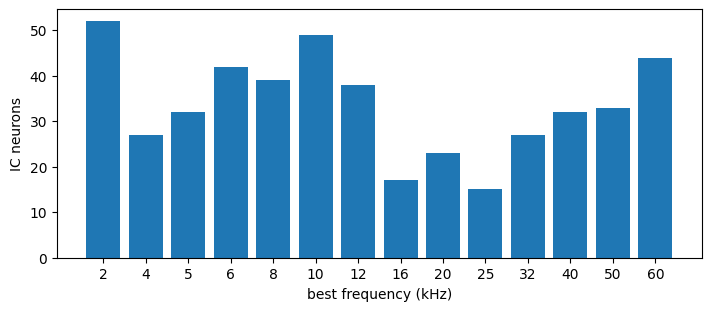

In [5]:
bfs = np.array([m["best_freq_khz"] for m in ds.nrn_meta if m["best_freq_khz"] is not None])
n_none = sum(m["best_freq_khz"] is None for m in ds.nrn_meta)
print(f"{n_none} of {ds.N_neurons} IC neurons respond to none of the 70-dB tones (best_freq_khz = None)")
freqs = sorted(set(bfs))
counts = [int((bfs == f).sum()) for f in freqs]
fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
ax.bar(range(len(freqs)), counts, color="tab:blue")
ax.set_xticks(range(len(freqs)), [f"{f:g}" for f in freqs])
ax.set_xlabel("best frequency (kHz)")
ax.set_ylabel("IC neurons")
plt.show()

**Best frequencies.** Each bar counts the IC neurons whose largest 70-dB tone
response is at that frequency; the 81 neurons that respond to no tone are left
out. Best frequencies span the whole tested range. The 2 and 60 kHz bars are
the ends of that range, so they also collect neurons tuned beyond it.

## Train / val / test split

`group_split` keeps together the sounds that share audio (50 / 70 dB copies,
and each decomposed clip's reconstruction with its components) and draws the
rest category by category. The draw covers all 307 sounds, so a seed gives
the same split whichever area is loaded.

In [6]:
split = ds.group_split(seed=0)
cats = sorted(set(m["category"] for m in ds.stim_meta))
print(f"{'category':18s} train  val test")
for c in cats:
    row = [sum(ds.stim_meta[i]["category"] == c for i in split[k]) for k in ("train", "val", "test")]
    print(f"{c:18s} {row[0]:5d} {row[1]:4d} {row[2]:4d}")
print(f"{'total':18s} {len(split['train']):5d} {len(split['val']):4d} {len(split['test']):4d}")

category           train  val test
am                    33    5   10
broad_chords           7    1    2
broad_noises          10    1    3
chirps_frequency       7    1    2
chirps_velocity        7    1    2
complex_sounds        42    6   12
decompositions        47    0    0
harmonic_chords        4    0    1
high_chords            8    1    2
low_chords             8    1    2
medium_chords          8    1    2
narrow_noises          7    1    2
pure_tones            20    2    6
ramps                 18    3    5
white_noises           4    1    1
total                230   25   52


## Auditory cortex (2-photon)

AC has its own time base (43.5 ms imaging bins) and is loaded on its own. The
values are deconvolved calcium signals: signed, smoothed, and lagging firing
by about 100 ms.

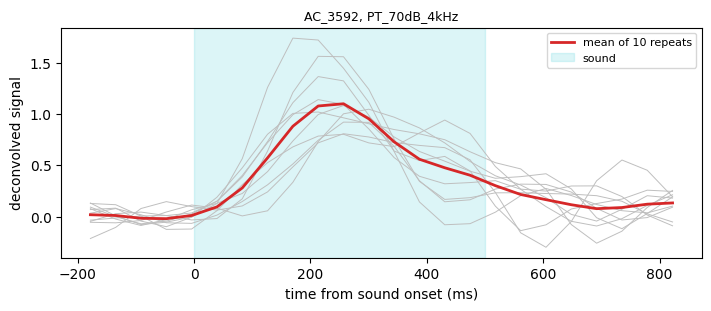

4217 AC neurons; recording type: 2p-calcium, indicator: GCaMP6s


In [7]:
ds_ac = Gosselin2025Dataset(PATH, areas=("AC",), download=PATH is None)
names_ac = [m["name"] for m in ds_ac.stim_meta]
best, best_val = None, -np.inf
for n, meta in enumerate(ds_ac.nrn_meta):
    if meta["best_freq_khz"] is None:
        continue
    s = names_ac.index(f"PT_70dB_{meta['best_freq_khz']:g}kHz")
    v = ds_ac.responses[s][n].mean(0)[5:16].mean().item()
    if v > best_val:
        best, best_val = (n, s), v
n, s = best
r = ds_ac.responses[s][n].numpy()
t_ac = np.arange(r.shape[1]) * ds_ac.dt - 200 + ds_ac.dt / 2      # bin centres, ms from onset
fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
ax.plot(t_ac, r.T, color="0.75", lw=0.7)
ax.plot(t_ac, r.mean(0), color="tab:red", lw=2, label=f"mean of {r.shape[0]} repeats")
ax.axvspan(0, 500, color="tab:cyan", alpha=0.15, label="sound")
ax.set_xlabel("time from sound onset (ms)")
ax.set_ylabel("deconvolved signal")
ax.set_title(f"{ds_ac.nrn_meta[n]['cell_id']}, {names_ac[s]}", fontsize=9)
ax.legend(fontsize=8)
plt.show()
print(f"{ds_ac.N_neurons} AC neurons; recording type: {ds_ac.recording_type}, "
      f"indicator: {ds_ac.indicator}")

**A 2-photon AC neuron.** Grey: the 10 individual repeats; red: their mean;
shaded: the 500-ms tone. This is the AC neuron with the strongest mean
response to its best 70-dB tone (4 kHz). The deconvolved signal starts rising
only ~50 ms after the onset, peaks around 250 ms and stays elevated after the
sound ends: the slow GCaMP6s kinetics that the deconvolution does not fully
remove. A model of AC needs a temporal context of several hundred ms.